# Student 1 Mathematical Signal and DTFT

Two sinusoidal components with Gaussian noise. The DTFT is calculated using loops. Run the cells from top to bottom.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## Generate the clean signal

64 samples with angular frequencies pi/4 and pi/2 radians per sample.


In [ ]:
sample_count = 64
n = np.arange(sample_count)

amplitude_1 = 1.0
amplitude_2 = 0.5
omega_1 = np.pi / 4
omega_2 = np.pi / 2

sine_1 = amplitude_1 * np.sin(omega_1 * n)
sine_2 = amplitude_2 * np.sin(omega_2 * n)
clean_signal = sine_1 + sine_2

## Add Gaussian noise

Mean 0, standard deviation 0.2, and random seed 7.


In [ ]:
noise_standard_deviation = 0.2
rng = np.random.default_rng(7)
noise = rng.normal(0.0, noise_standard_deviation, sample_count)
noisy_signal = clean_signal + noise

## Calculate the DTFT manually

The outer loop selects a frequency and the inner loop sums the sample contributions.


In [ ]:
def manual_dtft(signal, frequencies):
    spectrum = np.zeros(len(frequencies), dtype=complex)

    for m in range(len(frequencies)):
        w = frequencies[m]
        total = 0j

        for n in range(len(signal)):
            total += signal[n] * np.exp(-1j * w * n)

        spectrum[m] = total

    return spectrum

frequencies = np.linspace(-np.pi, np.pi, 513)
spectrum = manual_dtft(noisy_signal, frequencies)

## Calculate magnitude and phase

Phase is measured in radians.


In [ ]:
magnitude = np.abs(spectrum)
phase = np.angle(spectrum)
phase[magnitude < 1e-10 * magnitude.max()] = np.nan

## Plot the results


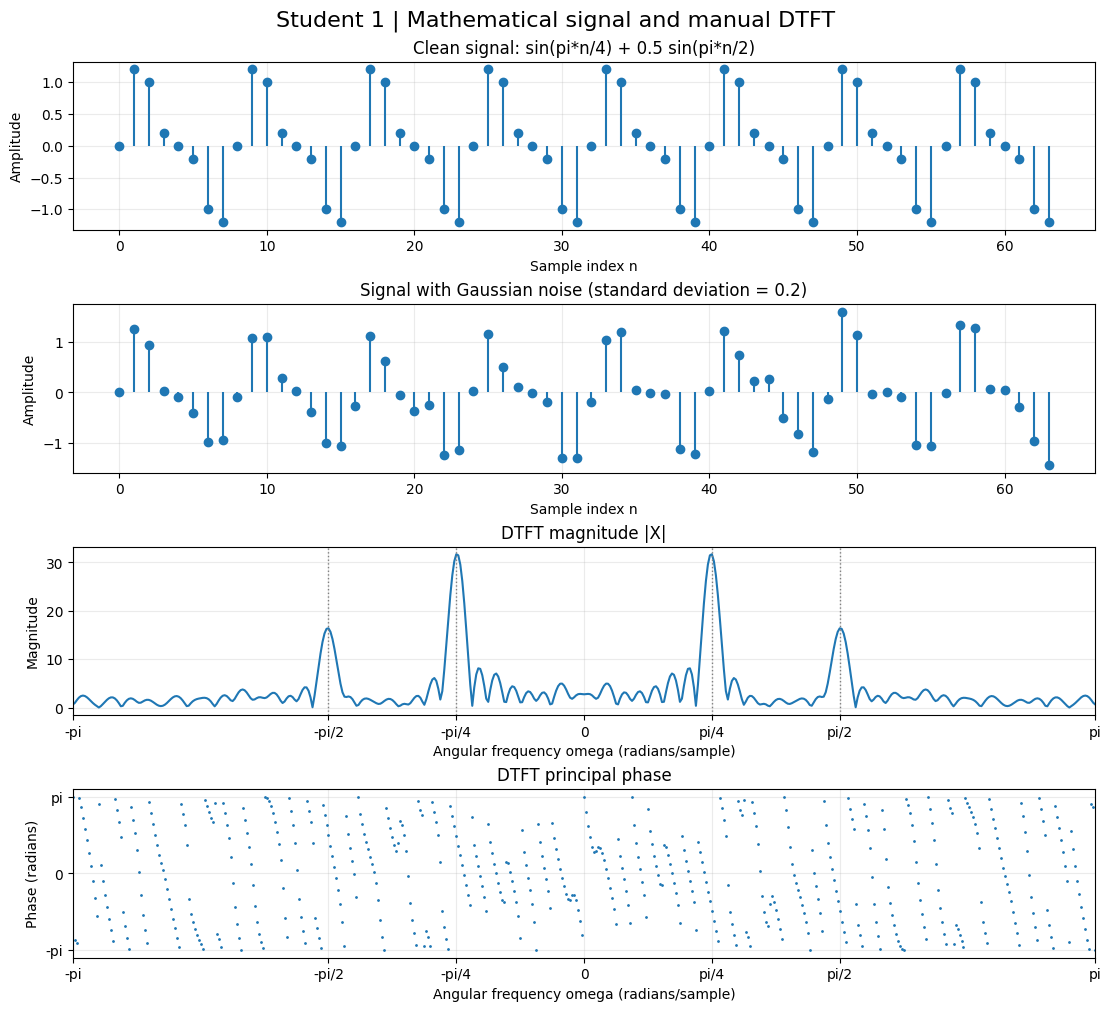

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(11, 10), layout="constrained")
fig.suptitle("Student 1 | Mathematical signal and manual DTFT", fontsize=16)

axes[0].stem(n, clean_signal, basefmt=" ")
axes[0].set_title("Clean signal: sin(pi*n/4) + 0.5 sin(pi*n/2)")
axes[0].set_xlabel("Sample index n")
axes[0].set_ylabel("Amplitude")

axes[1].stem(n, noisy_signal, basefmt=" ")
axes[1].set_title("Signal with Gaussian noise (standard deviation = 0.2)")
axes[1].set_xlabel("Sample index n")
axes[1].set_ylabel("Amplitude")

axes[2].plot(frequencies, magnitude)
axes[2].set_title("DTFT magnitude |X|")
axes[2].set_ylabel("Magnitude")
for w in (-omega_2, -omega_1, omega_1, omega_2):
    axes[2].axvline(w, color="0.5", linestyle=":", linewidth=1)

axes[3].plot(frequencies, phase, ".", markersize=2)
axes[3].set_title("DTFT principal phase")
axes[3].set_ylabel("Phase (radians)")
axes[3].set_yticks([-np.pi, 0, np.pi], ["-pi", "0", "pi"])

for ax in axes[2:]:
    ax.set_xlabel("Angular frequency omega (radians/sample)")
    ax.set_xlim(-np.pi, np.pi)
    ax.set_xticks(
        [-np.pi, -np.pi / 2, -np.pi / 4, 0, np.pi / 4, np.pi / 2, np.pi],
        ["-pi", "-pi/2", "-pi/4", "0", "pi/4", "pi/2", "pi"],
    )

for ax in axes:
    ax.grid(True, alpha=0.25)

fig.savefig("student1_dtft_plots.png", dpi=150)
plt.show()

# Student 2 Convolution and Difference Equations

#Moving Average Filter

Moving Average coefficients: [0.2 0.2 0.2 0.2 0.2]
Sum of coefficients: 1.0


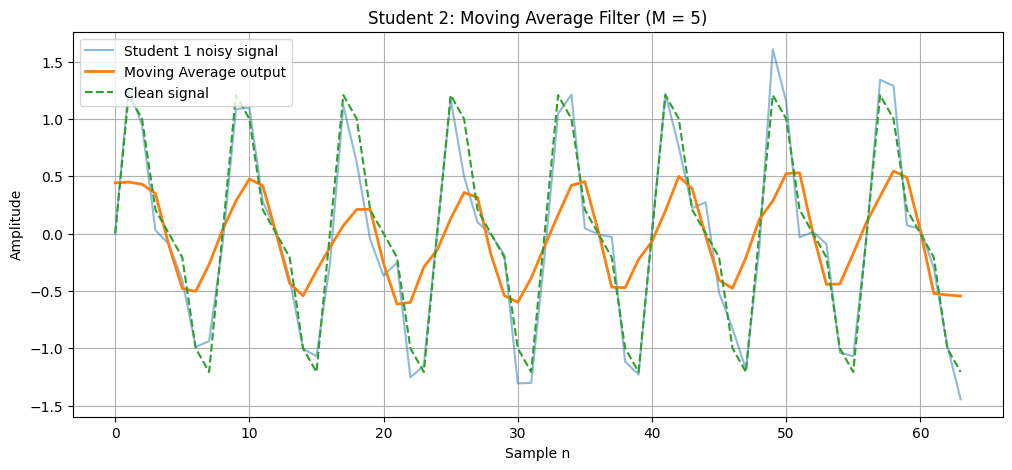

In [ ]:
M = 5

moving_average_filter = np.ones(M) / M

print("Moving Average coefficients:", moving_average_filter)
print("Sum of coefficients:", np.sum(moving_average_filter))

filtered_signal = np.convolve(
    noisy_signal,
    moving_average_filter,
    mode="same"
)

plt.figure(figsize=(12, 5))
plt.plot(n, noisy_signal, label="Student 1 noisy signal", alpha=0.5)
plt.plot(n, filtered_signal, label="Moving Average output", linewidth=2)
plt.plot(n, clean_signal, "--", label="Clean signal")
plt.title(f"Student 2: Moving Average Filter (M = {M})")
plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

#Time-Domain Convolution vs. Frequency-Domain Multiplication

In [ ]:
y_time = np.convolve(
    noisy_signal,
    moving_average_filter,
    mode="full"
)

Lx = len(noisy_signal)
Lh = len(moving_average_filter)
N = Lx + Lh - 1

X_fft = np.fft.fft(noisy_signal, n=N)
H_fft = np.fft.fft(moving_average_filter, n=N)

Y_fft = X_fft * H_fft
y_frequency = np.fft.ifft(Y_fft).real

print("Input length:", Lx)
print("Filter length:", Lh)
print("Required FFT length:", N)
print("Time-domain output length:", len(y_time))
print("Frequency-domain output length:", len(y_frequency))

max_difference = np.max(np.abs(y_time - y_frequency))
print("Maximum absolute difference:", max_difference)

Input length: 64
Filter length: 5
Required FFT length: 68
Time-domain output length: 68
Frequency-domain output length: 68
Maximum absolute difference: 3.3306690738754696e-16


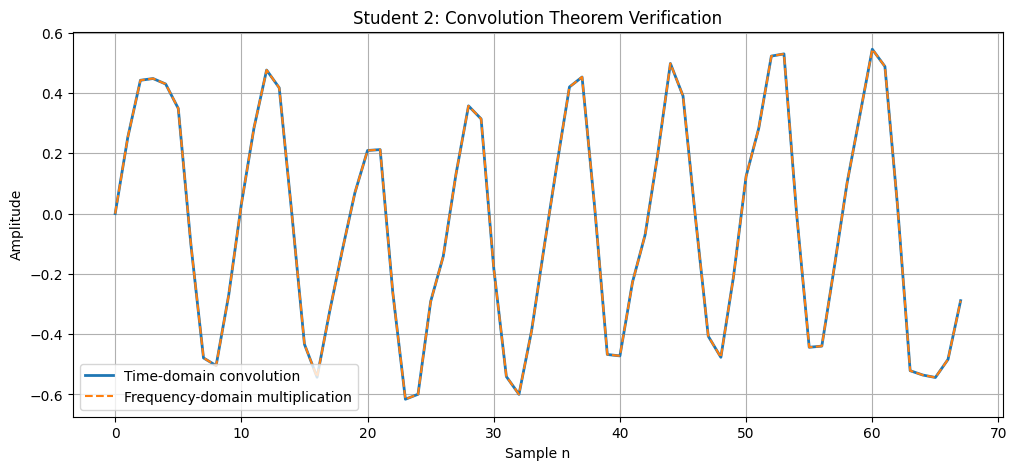

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(y_time, label="Time-domain convolution", linewidth=2)
plt.plot(y_frequency, "--", label="Frequency-domain multiplication")
plt.title("Student 2: Convolution Theorem Verification")
plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

#First-Order Difference Equation

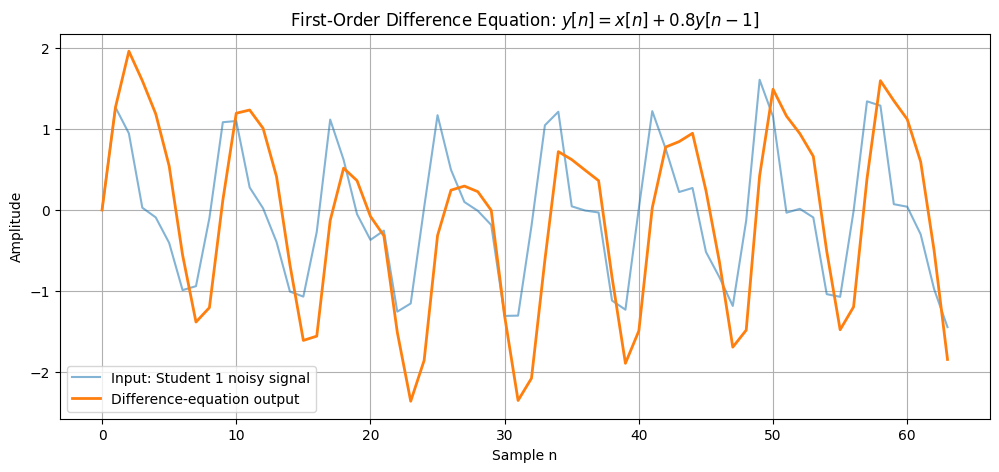

In [ ]:
a = 0.8
recursive_output = np.zeros(len(noisy_signal))

# Implement y[n] = x[n] + a*y[n-1]
for i in range(len(noisy_signal)):
    if i == 0:
        recursive_output[i] = noisy_signal[i]  # initial rest: y[-1] = 0
    else:
        recursive_output[i] = (
            noisy_signal[i] + a * recursive_output[i - 1]
        )

plt.figure(figsize=(12, 5))
plt.plot(noisy_signal, label="Input: Student 1 noisy signal", alpha=0.55)
plt.plot(recursive_output, label="Difference-equation output", linewidth=2)
plt.title(r"First-Order Difference Equation: $y[n]=x[n]+0.8y[n-1]$")
plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

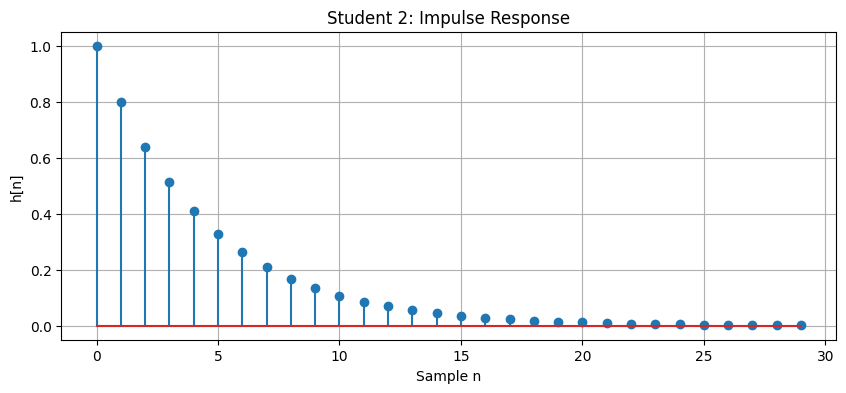

First 10 impulse-response samples:
[1.         0.8        0.64       0.512      0.4096     0.32768
 0.262144   0.2097152  0.16777216 0.13421773]


In [ ]:
impulse_length = 30
impulse = np.zeros(impulse_length)
impulse[0] = 1

impulse_response = np.zeros(impulse_length)

for i in range(impulse_length):
    if i == 0:
        impulse_response[i] = impulse[i]
    else:
        impulse_response[i] = (
            impulse[i] + a * impulse_response[i - 1]
        )

plt.figure(figsize=(10, 4))
plt.stem(np.arange(impulse_length), impulse_response)
plt.title("Student 2: Impulse Response")
plt.xlabel("Sample n")
plt.ylabel("h[n]")
plt.grid(True)
plt.show()

print("First 10 impulse-response samples:")
print(impulse_response[:10])